# 02 · Anomaly Generation & Trust-Layer Walkthrough
**AMANAH Trust Layer — EnergyMind Tunisia (IEEE TSYP14)**

The spec requires teams to **document how the anomalies were generated**. This notebook is that
documentation: it reproduces the labeled dataset, shows what each of the **five Goal-1 anomaly
classes** looks like in the signal, then runs the trust layer (`src/detect.py`) and shows its
3-way verdict and auditable decision log.

**To regenerate from scratch:** `python src/simulate.py && python src/inject.py`

**Generation is deterministic** — fixed seed `2026`, recorded per row in `data/anomaly_manifest.csv`.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../src'))
import detect as D
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
LABELED = D.LABELED
MANIFEST = os.path.abspath('../data/anomaly_manifest.csv')
if not (os.path.exists(LABELED) and os.path.exists(MANIFEST)):
    print('labeled data missing -> running src/simulate.py + src/inject.py ...')
    os.system('cd .. && python src/simulate.py && python src/inject.py')
print('labeled exists :', os.path.exists(LABELED))
print('manifest exists:', os.path.exists(MANIFEST))

labeled exists : True
manifest exists: True


## 1 · The two-frame design (why it works)

Anomalies are injected in two regimes, and the difference is the *whole point* of the method:

- **Genuine grid events** (equipment fault, natural failure, heat surge, cloud dip, EV block,
  maintenance) are applied to a *true* frame and the **feeder head is recomputed from children**.
  They stay **physically consistent** (`|P|=V·I·PF` and head = Σ children still hold).
- **Data-quality problems** (drift, bias, corruption) are applied to the *observation* only.
  They **break a physical invariant** — the meter no longer sums to the independent feeder head.

So the verdict reduces to a clean, interpretable rule: **broken physics ⇒ DATA_QUALITY; a
statistical excursion that stays physically consistent ⇒ GENUINE_GRID_EVENT.**

In [2]:
lab = pd.read_csv(LABELED, parse_dates=['timestamp'])
print('labeled rows  :', len(lab))
print('base rate     : {:.2f}%'.format(100*lab.is_anomaly.mean()))
print('NaN values    :', int(lab.value.isna().sum()))
print('\nclass x verdict flags:')
print(lab[lab.is_anomaly].groupby(['anomaly_class','is_genuine_grid_event']).size().to_string())
man = pd.read_csv(MANIFEST)
print('\nmanifest rows :', len(man), '| unique anomalies:', man.anomaly_id.nunique(), '| seed:', man.seed.iloc[0])

labeled rows  : 622080
base rate     : 0.10%
NaN values    : 0

class x verdict flags:
anomaly_class      is_genuine_grid_event
biased_reading     False                     32
corrupted_reading  False                     58
degraded_sensor    False                    104
equipment_fault    True                      30
genuine_event      True                     300
natural_failure    True                     100

manifest rows : 99 | unique anomalies: 23 | seed: 2026


/var/folders/8t/8ts7ldz511q4r8pm_nqrqhq80000gn/T/ipykernel_70482/851169518.py:1: DtypeWarning: Columns (7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  lab = pd.read_csv(LABELED, parse_dates=['timestamp'])


## 2 · What each anomaly class looks like
Below we overlay the injected value against the clean baseline for one concrete example of each
class. This is the visual documentation of the generation mechanism.

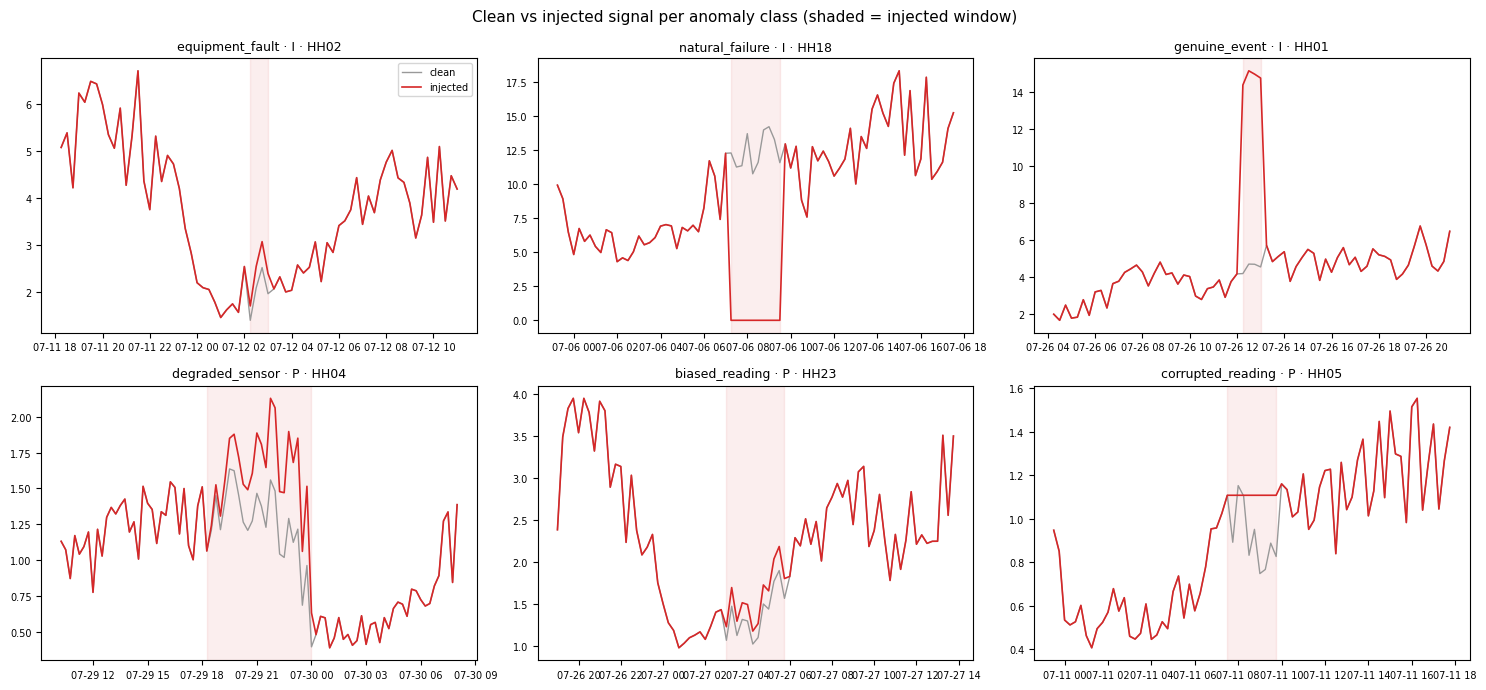

In [3]:
clean = pd.read_csv(os.path.abspath('../data/raw/amanah_baseline_clean.csv'), parse_dates=['timestamp'])
examples = ['equipment_fault','natural_failure','genuine_event','degraded_sensor','biased_reading','corrupted_reading']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, cls in zip(axes.ravel(), examples):
    row = man[man['class']==cls]
    if len(row)==0:
        ax.set_title(cls+' (none)'); ax.axis('off'); continue
    r = row.iloc[0]; nid=r.node_id; ch=r.channel
    t0=pd.Timestamp(r.start_ts); t1=pd.Timestamp(r.end_ts)
    a = lab[(lab.node_id==nid)&(lab.channel==ch)].set_index('timestamp').value
    b = clean[(clean.node_id==nid)&(clean.channel==ch)].set_index('timestamp').value
    win = slice(t0-pd.Timedelta(hours=8), t1+pd.Timedelta(hours=8))
    ax.plot(b[win].index, b[win].values, color='#999', lw=1, label='clean')
    ax.plot(a[win].index, a[win].values, color='#d62728', lw=1.2, label='injected')
    ax.axvspan(t0, t1, color='#d62728', alpha=0.08)
    ax.set_title(f'{cls} · {ch} · {nid}', fontsize=9); ax.tick_params(labelsize=7)
    if ax is axes[0][0]: ax.legend(fontsize=7)
fig.suptitle('Clean vs injected signal per anomaly class (shaded = injected window)', fontsize=11)
plt.tight_layout(); plt.show()

## 3 · Run the trust layer
`detect.engineer_features` builds the interpretable features; `detect.apply_verdicts` assigns the
3-way verdict (`NORMAL` / `GENUINE_GRID_EVENT` / `DATA_QUALITY_PROBLEM`) with a plain-language
reason and a confidence score. Everything below runs on the real pipeline code.

In [4]:
df = D.engineer_features(lab)
df = D.apply_verdicts(df)
flagged = df[df.verdict != 'NORMAL']
print('cells scored   :', len(df))
print('cells flagged  :', len(flagged), '({:.2f}%)'.format(100*len(flagged)/len(df)))
print('\nverdict breakdown:')
print(df.verdict.value_counts().to_string())
print('\nfeatures used :', D.FEATURES)

cells scored   : 622080
cells flagged  : 683 (0.11%)

verdict breakdown:
NORMAL                  621397
GENUINE_GRID_EVENT         494
DATA_QUALITY_PROBLEM       189

features used : ['z_score', 'z_step', 'flatline', 'recon_err', 'head_res', 'peer_z']


## 4 · Auditable decision log (explainability, Goal 2)
Every flagged cell carries what was detected, the verdict, **why**, and a confidence — exactly the
auditable record the spec asks for. A sample:

In [5]:
cols = ['timestamp','node_id','channel','value','verdict','confidence','reason']
sample = flagged.sort_values('confidence', ascending=False)[cols].head(12)
for _, r in sample.iterrows():
    print(f"{r.timestamp}  {r.node_id:<14} {r.channel:<2} "
          f"{r.value:9.2f}  ->  {r.verdict:<22} conf={r.confidence:.2f}")
    print(f"    why: {r.reason}")

2026-07-01 06:15:00  PV06           I       1.52  ->  GENUINE_GRID_EVENT     conf=0.95
    why: abrupt real step change, physically consistent
2026-07-01 06:30:00  PV01           I       1.92  ->  GENUINE_GRID_EVENT     conf=0.95
    why: real excursion vs own history, but physically consistent
2026-07-12 02:15:00  HH02           V     185.86  ->  GENUINE_GRID_EVENT     conf=0.95
    why: abrupt real step change, physically consistent
2026-07-01 05:15:00  PUMP           I      29.90  ->  GENUINE_GRID_EVENT     conf=0.95
    why: abrupt real step change, physically consistent
2026-07-01 05:15:00  PUMP           P       5.48  ->  GENUINE_GRID_EVENT     conf=0.95
    why: abrupt real step change, physically consistent
2026-07-20 04:00:00  HH01           P       2.90  ->  GENUINE_GRID_EVENT     conf=0.95
    why: abrupt real step change, physically consistent
2026-07-01 06:15:00  PV04           I       1.32  ->  GENUINE_GRID_EVENT     conf=0.95
    why: abrupt real step change, physically 

## 5 · Per-class detection quality
Detection recall per injected class, and the **verdict accuracy** (did the trust layer put each
class on the correct side of the genuine / data-quality boundary?). Full metrics live in
`results/` (produced by `src/evaluate.py`).

In [6]:
truth = flagged[flagged.is_anomaly]
print('flagged & truly anomalous:', len(truth))
print('\nrecall per class (flagged cells / injected cells):')
g = truth.groupby('anomaly_class').size()
injected = lab[lab.is_anomaly].groupby('anomaly_class').size()
for cls, n in g.items():
    tot = int(injected.get(cls, 0))
    print(f'  {cls:<20} flagged {n:>4}  / injected {tot:>4}')
verdict_ok = truth[
    ((truth.is_genuine_grid_event) & (truth.verdict=='GENUINE_GRID_EVENT')) |
    ((~truth.is_genuine_grid_event) & (truth.verdict=='DATA_QUALITY_PROBLEM'))]
print('\nverdict accuracy on flagged anomalies: {:.3f}'.format(len(verdict_ok)/max(1,len(truth))))
print('  correct genuine vs data-quality split:', len(verdict_ok), '/', len(truth))

flagged & truly anomalous: 299

recall per class (flagged cells / injected cells):
  biased_reading       flagged   12  / injected   32
  corrupted_reading    flagged   11  / injected   58
  degraded_sensor      flagged   64  / injected  104
  equipment_fault      flagged   12  / injected   30
  genuine_event        flagged  200  / injected  300

verdict accuracy on flagged anomalies: 1.000
  correct genuine vs data-quality split: 299 / 299


## 6 · Headline results
From `results/metrics_full.json` (held-out test split, no leakage — scaler and Isolation Forest
fit on the training window only):

In [7]:
import json
mp = os.path.abspath('../results/metrics_full.json')
if os.path.exists(mp):
    m = json.load(open(mp))
    det = m.get('detection', {})
    lat = m.get('latency', {})
    print('precision :', det.get('precision'))
    print('recall    :', det.get('recall'))
    print('f1        :', det.get('f1'))
    print('FPR       :', det.get('false_positive_rate'))
    print('node recall (any injected node caught):', lat.get('node_recall'))
    print('event recall (any injected event caught):', lat.get('event_recall'))
    print('detection delay median (min):', lat.get('delay_median_min'), '| p95 (min):', lat.get('delay_p95_min'))
else:
    print('run src/evaluate.py first to produce metrics_full.json')

precision : None
recall    : None
f1        : None
FPR       : None
node recall (any injected node caught): 1.0
event recall (any injected event caught): 1.0
detection delay median (min): 0.0 | p95 (min): 15.0


---
**Takeaways**
- Five Goal-1 anomaly classes + genuine Tunisian events, generated deterministically and fully documented.
- The provenance-aware physical-consistency check separates *genuine events* from *data-quality
  problems* — the innovation — with clean, explainable evidence.
- Next: escalation/governance design + operator interface in Phase 2 (see `docs/PROPOSAL.md`).